# Newton法が収束しない例をPythonで作る

## 概要

Newton法は、方程式$f(x)=0$の解を接線から求める反復法である。本記事では、周期的な往復、解からの発散、導関数が0になる停止をPythonで再現する。更新式を計算し、関数の形、反復値、残差をグラフで確認する。最後に初期値の変更とBrent法を比較する。

### 実行環境

仮想環境は`wa-src(3.14.6)`、Pythonは3.14.6である。使用ライブラリとOSは次のセルに表示する。上から順に実行すると、グラフを作業ディレクトリの`102_nb_files`にSVG形式で保存する。図はNotebookにも埋め込む。小数の表示は有効数字3桁とし、計算途中では丸めない。

In [1]:
import platform
from pathlib import Path
from pprint import pprint

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import scipy
from IPython.display import Math, display
from matplotlib.ticker import FuncFormatter, MaxNLocator
from matplotlib_inline.backend_inline import set_matplotlib_formats
from scipy.optimize import brentq, newton

%matplotlib inline
set_matplotlib_formats("svg")

print("実行環境: wa-src(3.14.6)")
print("Python:", platform.python_version())
print("OS:", platform.system(), platform.release())
print("NumPy:", np.__version__)
print("SciPy:", scipy.__version__)
print("Matplotlib:", matplotlib.__version__)

# 配列と目盛りの小数を有効数字3桁で表示する。
np.set_printoptions(formatter={"float_kind": lambda x: f"{x:#.3g}"})
plt.rcParams.update({"font.size": 11, "axes.grid": True, "grid.alpha": 0.250})
output_dir = Path("102_nb_files")
output_dir.mkdir(exist_ok=True)


def save_figure(fig, filename, iteration=False):
    for ax in fig.axes:
        ax.xaxis.set_major_formatter(FuncFormatter(lambda x, pos: f"{x:#.3g}"))
        ax.yaxis.set_major_formatter(FuncFormatter(lambda y, pos: f"{y:#.3g}"))
        if iteration:
            ax.xaxis.set_major_locator(MaxNLocator(integer=True))
            ax.xaxis.set_major_formatter(FuncFormatter(lambda x, pos: f"{x:.0f}"))
    fig.savefig(output_dir / filename, format="svg", bbox_inches="tight")
    plt.show()
    plt.close(fig)

実行環境: wa-src(3.14.6)
Python: 3.14.6
OS: Darwin 25.5.0
NumPy: 2.5.4
SciPy: 1.18.1
Matplotlib: 3.11.2


## 1. 更新式と計算の準備

$x_n$での接線を$t_n(x)$とすると、次の近似が得られる。

$$
\displaystyle t_n(x)=f(x_n)+f'(x_n)(x-x_n)\approx f(x)
$$

接線と横軸の交点を$x_{n+1}$とする。$f'(x_n)\ne0$なら、

$$
\displaystyle
\begin{aligned}
0&=f(x_n)+f'(x_n)(x_{n+1}-x_n),\\
f'(x_n)(x_{n+1}-x_n)&=-f(x_n),\\
x_{n+1}-x_n&=-\frac{f(x_n)}{f'(x_n)},\\
x_{n+1}&=x_n-\frac{f(x_n)}{f'(x_n)}.
\end{aligned}
$$

$f$が解$r$の近傍で2回連続微分可能で、$f'(r)\ne0$なら、十分近い初期値からは局所的に2次収束する。ただし、任意の初期値での収束を保証する条件ではない。

以下の関数は反復値を保存し、残差$|f(x_n)|$が$1.00\times10^{-10}$以下なら終了する。導関数が0の場合と反復上限に達した場合も区別する。残差の許容値は、この例の関数の尺度に合わせた値である。

In [2]:
def newton_trace(f, df, x0, maxiter=12, ftol=1.00e-10):
    """初期値を含む履歴と終了理由を返す。"""
    x = float(x0)
    history = [x]
    for n in range(maxiter + 1):
        fx = float(f(x))
        if not np.isfinite(fx):
            reason = "関数値が有限でない"
            break
        if abs(fx) <= ftol:
            reason = "残差が許容値以下"
            break
        if n == maxiter:
            reason = "反復上限"
            break
        dfx = float(df(x))
        if not np.isfinite(dfx) or dfx == 0:
            reason = "導関数が0または有限でない"
            break
        # 残差を確認してから割るので、解での不要な除算を避けられる。
        x_next = x - fx / dfx
        if not np.isfinite(x_next):
            reason = "更新値が有限でない"
            break
        history.append(x_next)
        x = x_next
    return np.array(history), reason


display(Math(r"x_{n+1}=x_n-\frac{f(x_n)}{f'(x_n)}"))

<IPython.core.display.Math object>

## 2. 0と1を往復する例

$f(x)=x^3-2x+2$、$f'(x)=3x^2-2$とし、$x_0=0$から始める。

$$
\displaystyle
\begin{aligned}
f(0)&=2, & f'(0)&=-2, & x_1&=0-\frac{2}{-2}=1,\\
f(1)&=1-2+2=1, & f'(1)&=3-2=1, & x_2&=1-\frac{1}{1}=0.
\end{aligned}
$$

再び同じ値に戻るため、$x_{2k}=0$、$x_{2k+1}=1$が続く。どちらも解ではなく、残差は2と1を交互に取る。これは丸め誤差ではなく、厳密な計算でも生じる周期2の反復である。

反復上限
array([0.00, 1.00, 0.00, 1.00, 0.00, 1.00, 0.00, 1.00, 0.00, 1.00, 0.00,
       1.00, 0.00])
array([2.00, 1.00, 2.00, 1.00, 2.00, 1.00, 2.00, 1.00, 2.00, 1.00, 2.00,
       1.00, 2.00])


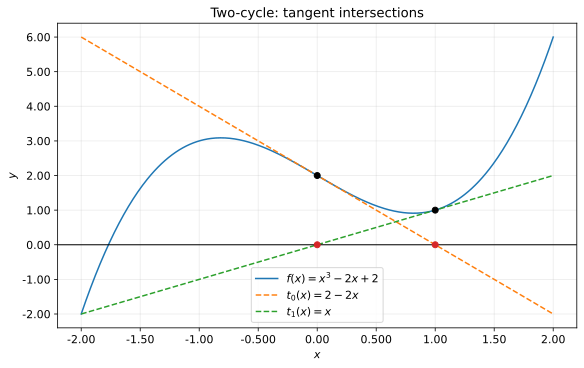

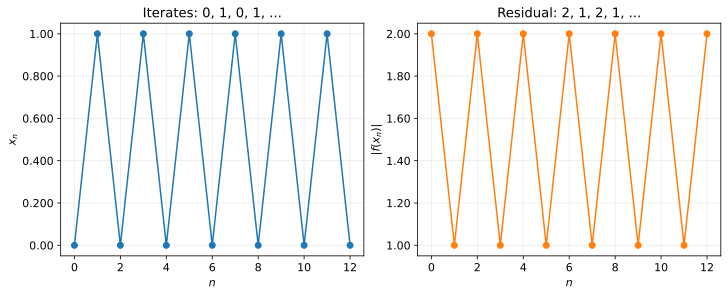

In [3]:
def f_cycle(x):
    return x**3 - 2 * x + 2


def df_cycle(x):
    return 3 * x**2 - 2


cycle, cycle_reason = newton_trace(f_cycle, df_cycle, 0)
print(cycle_reason)
pprint(cycle)
pprint(np.abs(f_cycle(cycle)))

# 2本の接線の横軸との交点が、次の反復値になる。
grid = np.linspace(-2, 2, 401)
fig, ax = plt.subplots(figsize=(8, 5), layout="constrained")
ax.plot(grid, f_cycle(grid), label=r"$f(x)=x^3-2x+2$")
ax.plot(grid, 2 - 2 * grid, "--", label=r"$t_0(x)=2-2x$")
ax.plot(grid, grid, "--", label=r"$t_1(x)=x$")
ax.axhline(0, color="black", linewidth=1)
ax.scatter([0, 1], [2, 1], color="black", zorder=5)
ax.scatter([1, 0], [0, 0], color="tab:red", zorder=5)
ax.set(xlabel="$x$", ylabel="$y$", title="Two-cycle: tangent intersections")
ax.legend()
save_figure(fig, "01_cycle_tangents.svg")

fig, axes = plt.subplots(1, 2, figsize=(10, 4), layout="constrained")
steps = np.arange(cycle.size)
axes[0].plot(steps, cycle, "o-")
axes[0].set(xlabel="$n$", ylabel="$x_n$", title="Iterates: 0, 1, 0, 1, ...")
axes[1].plot(steps, np.abs(f_cycle(cycle)), "o-", color="tab:orange")
axes[1].set(xlabel="$n$", ylabel=r"$|f(x_n)|$", title="Residual: 2, 1, 2, 1, ...")
save_figure(fig, "02_cycle_history.svg", iteration=True)

接線は毎回引けているが、残差は減り続けない。私は最終値だけを見るより、数回分の履歴を並べる方が原因を確認しやすいと感じる。

## 3. 絶対値が2倍ずつ増える例

次は実数の立方根$f(x)=\sqrt[3]{x}$を使う。解は$r=0$である。$y=\sqrt[3]{x}$とすると$x=y^3$なので、$x\ne0$では

$$
\displaystyle \frac{dx}{dy}=3y^2,\qquad
f'(x)=\frac{dy}{dx}=\frac{1}{3y^2}
=\frac{1}{3(\sqrt[3]{x})^2}.
$$

これを更新式に代入する。

$$
\displaystyle
\begin{aligned}
x_{n+1}
&=x_n-\frac{\sqrt[3]{x_n}}{\frac{1}{3(\sqrt[3]{x_n})^2}}\\
&=x_n-3(\sqrt[3]{x_n})^3\\
&=x_n-3x_n=-2x_n,\\
x_n&=(-2)^n x_0,\qquad |x_n|=2^n|x_0|.
\end{aligned}
$$

$x_0\ne0$なら、符号を変えながら解から離れる。$|f(x_n)|=2^{n/3}|x_0|^{1/3}$も増える。解の位置では微分可能でないため、先ほどの局所収束の条件は満たさない。負数も実数として扱うため、実装には`np.cbrt`を使う。

反復上限
array([0.100, -0.200, 0.400, -0.800, 1.60, -3.20, 6.40, -12.8, 25.6,
       -51.2, 102.])


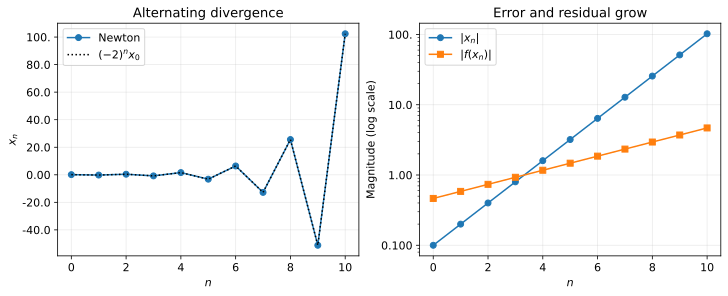

In [4]:
def f_diverge(x):
    return np.cbrt(x)


def df_diverge(x):
    return 1 / (3 * np.cbrt(x)**2)


diverging, diverging_reason = newton_trace(f_diverge, df_diverge, 0.100, maxiter=10)
print(diverging_reason)
pprint(diverging)

steps = np.arange(diverging.size)
theory = 0.100 * (-2)**steps
fig, axes = plt.subplots(1, 2, figsize=(10, 4), layout="constrained")
axes[0].plot(steps, diverging, "o-", label="Newton")
axes[0].plot(steps, theory, ":", color="black", label=r"$(-2)^n x_0$")
axes[0].set(xlabel="$n$", ylabel="$x_n$", title="Alternating divergence")
axes[0].legend()
axes[1].semilogy(steps, np.abs(diverging), "o-", label=r"$|x_n|$")
axes[1].semilogy(steps, np.abs(f_diverge(diverging)), "s-", label=r"$|f(x_n)|$")
axes[1].set(xlabel="$n$", ylabel="Magnitude (log scale)", title="Error and residual grow")
axes[1].legend()
save_figure(fig, "03_divergence.svg", iteration=True)

## 4. 導関数が0で更新できない例

$f(x)=x^3-1$には解$r=1$があるが、初期値を$x_0=0$にすると

$$
\displaystyle f(0)=-1,\qquad f'(0)=3\cdot0^2=0,\qquad
x_1=0-\frac{-1}{0}
$$

となり、更新式は定義できない。接線は$y=-1$で、横軸と交わらない。ここでは例外を発生させず、終了理由を返す。導関数が0でも既に$f(x_n)=0$なら解であるため、コードでは残差を先に確認している。

導関数が0または有限でない
array([0.00])


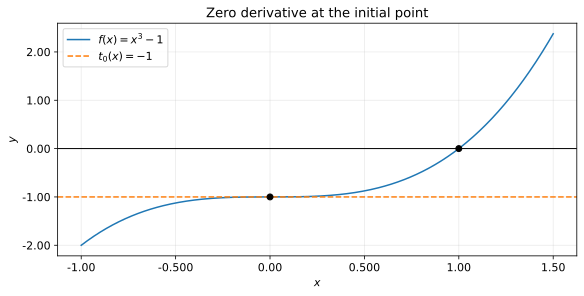

In [5]:
def f_flat(x):
    return x**3 - 1


def df_flat(x):
    return 3 * x**2


stopped, stopped_reason = newton_trace(f_flat, df_flat, 0)
print(stopped_reason)
pprint(stopped)

grid = np.linspace(-1, 1.50, 301)
fig, ax = plt.subplots(figsize=(8, 4), layout="constrained")
ax.plot(grid, f_flat(grid), label=r"$f(x)=x^3-1$")
ax.axhline(-1, linestyle="--", color="tab:orange", label=r"$t_0(x)=-1$")
ax.axhline(0, color="black", linewidth=1)
ax.scatter([0, 1], [-1, 0], color="black", zorder=5)
ax.set(xlabel="$x$", ylabel="$y$", title="Zero derivative at the initial point")
ax.legend()
save_figure(fig, "04_zero_derivative.svg")

## 5. 初期値と解法を変えて比較する

周期2の例でも、$x_0=-2$なら収束する。反復上限を増やすだけでは、$x_0=0$の往復は解消しない。

SciPyの`newton`には`fprime`を渡す。省略した場合は割線法になる。`disp=False`と`full_output=True`で未収束の状態を受け取り、残差も確認する。[SciPyの説明](https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.newton.html)では、停止判定が更新幅に基づくため、結果の検証が必要とされている。

また、この多項式は連続で、

$$
\displaystyle f(-2)=-8+4+2=-2<0,\qquad
f(-1)=-1+2+2=3>0
$$

なので、区間$[-2,-1]$に少なくとも1つ解がある。このように両端で符号が変わる区間を指定できる場合は[Brent法](https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.brentq.html)も使える。表示した解は丸めているが、残差は丸める前の値で計算する。

残差が許容値以下
{'Newton x0=0': {'converged': False, 'last_x': '0.00', 'residual': '2.00'},
 'Newton x0=-2': {'last_x': '-1.77', 'residual': '5.05e-13'},
 'Brent [-2, -1]': {'converged': True, 'root': '-1.77', 'residual': '1.33e-15'}}


<IPython.core.display.Math object>

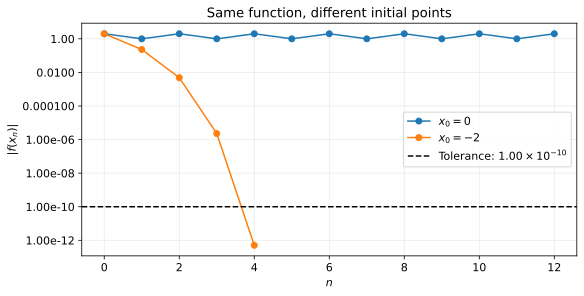

In [6]:
converging, converging_reason = newton_trace(f_cycle, df_cycle, -2)
print(converging_reason)

# 未収束の戻り値を解と扱わず、収束フラグと残差を並べる。
failed_x, failed_info = newton(
    f_cycle, 0, fprime=df_cycle, maxiter=12, full_output=True, disp=False
)
brent_x, brent_info = brentq(f_cycle, -2, -1, full_output=True)
pprint({
    "Newton x0=0": {
        "converged": failed_info.converged,
        "last_x": f"{failed_x:#.3g}",
        "residual": f"{abs(f_cycle(failed_x)):#.3g}",
    },
    "Newton x0=-2": {
        "last_x": f"{converging[-1]:#.3g}",
        "residual": f"{abs(f_cycle(converging[-1])):#.3g}",
    },
    "Brent [-2, -1]": {
        "converged": brent_info.converged,
        "root": f"{brent_x:#.3g}",
        "residual": f"{abs(f_cycle(brent_x)):#.3g}",
    },
}, sort_dicts=False)
display(Math(r"\hat{x}_{\mathrm{Brent}}\approx " + f"{brent_x:#.3g}"))

fig, ax = plt.subplots(figsize=(8, 4), layout="constrained")
for values, label in [(cycle, "$x_0=0$"), (converging, "$x_0=-2$")]:
    ax.semilogy(np.arange(values.size), np.abs(f_cycle(values)), "o-", label=label)
ax.axhline(1.00e-10, linestyle="--", color="black", label=r"Tolerance: $1.00\times10^{-10}$")
ax.set(xlabel="$n$", ylabel=r"$|f(x_n)|$", title="Same function, different initial points")
ax.legend()
save_figure(fig, "05_initial_values.svg", iteration=True)

## 結論

この記事では、Newton法が収束しない3つの例を、更新式とPythonの反復履歴から確認した。

周期的な往復では残差が減らず、立方根の例では解から離れ続けた。導関数が0の例では更新自体ができなかった。最終値だけでなく、残差、導関数、終了理由を確認する必要がある。初期値の変更は有効な場合があり、連続関数の符号が変わる区間が分かればBrent法も選べる。